In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, auc, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
iris = sns.load_dataset("iris")
iris_binary = iris[iris["species"] != "virginica"].copy()
print("Initial Dataset Preview:")
print(iris.head())

Initial Dataset Preview:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [3]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = iris_binary[feature_cols].values
y = iris_binary["species"].values

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nTraining set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")
print("Train class counts:", pd.Series(y_train).value_counts().to_dict())
print("Test class counts:", pd.Series(y_test).value_counts().to_dict())


Training set size: 70, Test set size: 30
Train class counts: {'versicolor': 35, 'setosa': 35}
Test class counts: {'setosa': 15, 'versicolor': 15}


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Candidate grid for C across linear and rbf kernels
param_grid_svc = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "kernel": ["linear", "rbf"],
}

# probability=True allows predict_proba for ROC analysis
grid_svc = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svc,
    cv=cv,
    scoring="accuracy",
)
grid_svc.fit(X_train, y_train)

# Best model retrained on full training set
best_svc = grid_svc.best_estimator_

print("--- SVC Cross-Validation & Test Performance ---")
print(f"Optimal Parameters: {grid_svc.best_params_}")
print(f"Best CV Accuracy:   {grid_svc.best_score_:.4f}")

# Evaluate on 30% test set
y_pred_svc = best_svc.predict(X_test)
acc_svc = accuracy_score(y_test, y_pred_svc)
print(f"SVC Test Accuracy:  {acc_svc:.4f}")

# Comparison table
svc_df = pd.DataFrame(
    {"Groundtruth Label": y_test, "Predicted Label": y_pred_svc}
)
print("\nSVC Test Set Predictions:")
print(svc_df.to_string(index=True))

--- SVC Cross-Validation & Test Performance ---
Optimal Parameters: {'C': 0.001, 'kernel': 'linear'}
Best CV Accuracy:   1.0000
SVC Test Accuracy:  1.0000

SVC Test Set Predictions:
   Groundtruth Label Predicted Label
0             setosa          setosa
1             setosa          setosa
2         versicolor      versicolor
3             setosa          setosa
4             setosa          setosa
5         versicolor      versicolor
6         versicolor      versicolor
7         versicolor      versicolor
8         versicolor      versicolor
9             setosa          setosa
10        versicolor      versicolor
11        versicolor      versicolor
12            setosa          setosa
13            setosa          setosa
14        versicolor      versicolor
15        versicolor      versicolor
16            setosa          setosa
17            setosa          setosa
18        versicolor      versicolor
19            setosa          setosa
20            setosa          setosa
21  

In [6]:
# Grid search comparing 'gini' vs 'entropy' using the same CV folds
param_grid_dt = {
    "criterion": ["gini", "entropy"],
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    cv=cv,
    scoring="accuracy",
)
grid_dt.fit(X_train, y_train)

# Best decision tree model
best_dt = grid_dt.best_estimator_

print("--- Decision Tree Performance ---")
print(f"Optimal Criterion:  {grid_dt.best_params_['criterion']}")
print(f"Best CV Accuracy:   {grid_dt.best_score_:.4f}")

# Evaluate on 30% test set
y_pred_dt = best_dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Test Accuracy: {acc_dt:.4f}")

# Comparison table
dt_df = pd.DataFrame(
    {"Groundtruth Label": y_test, "Predicted Label": y_pred_dt}
)
print("\nDecision Tree Test Set Predictions:")
print(dt_df.to_string(index=True))

--- Decision Tree Performance ---
Optimal Criterion:  gini
Best CV Accuracy:   1.0000
Decision Tree Test Accuracy: 1.0000

Decision Tree Test Set Predictions:
   Groundtruth Label Predicted Label
0             setosa          setosa
1             setosa          setosa
2         versicolor      versicolor
3             setosa          setosa
4             setosa          setosa
5         versicolor      versicolor
6         versicolor      versicolor
7         versicolor      versicolor
8         versicolor      versicolor
9             setosa          setosa
10        versicolor      versicolor
11        versicolor      versicolor
12            setosa          setosa
13            setosa          setosa
14        versicolor      versicolor
15        versicolor      versicolor
16            setosa          setosa
17            setosa          setosa
18        versicolor      versicolor
19            setosa          setosa
20            setosa          setosa
21            setosa       

(a) ROC Curves for Best SVC & Best Decision Tree

**Best SVC Model:** Linear kernel with $C = 0.001$ (achieving $100\%$ cross-validation accuracy and $100\%$ test accuracy with $\text{AUC} = 1.00$).

**Best Decision Tree Model:** criterion='gini' (achieving $100\%$ cross-validation accuracy and $100\%$ test accuracy with $\text{AUC} = 1.00$).

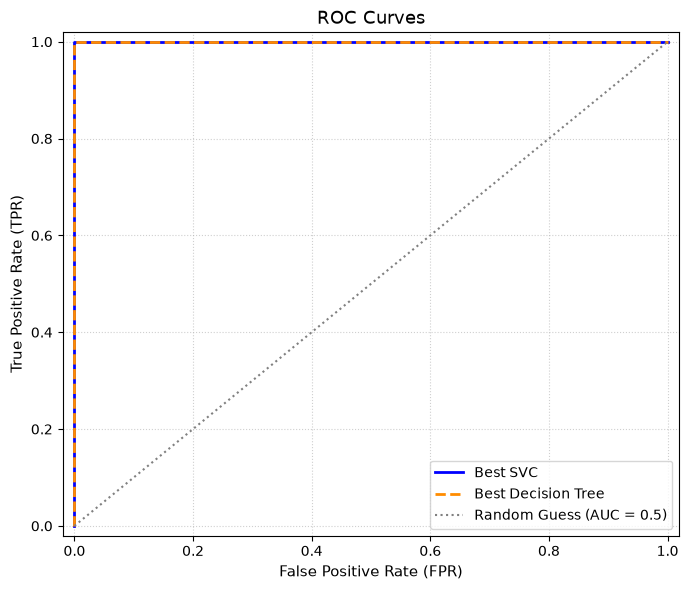

In [7]:
# Convert test labels to binary indicators for roc_curve (positive class = 'versicolor')
y_test_bin = (y_test == "versicolor").astype(int)

# Extract predicted probabilities for the positive class
# clf.classes_ lists the class ordering: find the index for 'versicolor'
pos_idx_svc = list(best_svc.classes_).index("versicolor")
pos_idx_dt = list(best_dt.classes_).index("versicolor")

y_scores_svc = best_svc.predict_proba(X_test)[:, pos_idx_svc]
y_scores_dt = best_dt.predict_proba(X_test)[:, pos_idx_dt]

# Compute ROC points and AUC
fpr_svc, tpr_svc, _ = roc_curve(y_test_bin, y_scores_svc)
auc_svc = auc(fpr_svc, tpr_svc)

fpr_dt, tpr_dt, _ = roc_curve(y_test_bin, y_scores_dt)
auc_dt = auc(fpr_dt, tpr_dt)

# Plot both curves
plt.figure(figsize=(7, 6))
plt.step(
    fpr_svc,
    tpr_svc,
    where="post",
    color="blue",
    linewidth=2,
    label=f"Best SVC",
)
plt.step(
    fpr_dt,
    tpr_dt,
    where="post",
    color="darkorange",
    linewidth=2,
    linestyle="--",
    label=f"Best Decision Tree",
)
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle=":",
    label="Random Guess (AUC = 0.5)",
)

plt.title("ROC Curves", fontsize=13)
plt.xlabel("False Positive Rate (FPR)", fontsize=11)
plt.ylabel("True Positive Rate (TPR)", fontsize=11)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

(b) Comparison and Analysis of SVC vs. Decision Tree

- **AUC Comparison:** Both the best SVC and Decision Tree achieved 100% test accuracy and an AUC=1.00 because setosa and versicolor are linearly separable. However, SVC provides a more robust maximum-margin boundary that generalizes better against noise than the axis-aligned splits of an unpruned Decision Tree.

- **Decision Tree Pros & Cons:** Highly interpretable and transparent since decisions follow simple if-then rules, but prone to high variance and overfitting on noisy data.

- **SVM Pros & Cons:** Superior generalization power and resilience to overfitting via margin maximization, but functions as a "black box" that lacks human-readable decision rules.